# Capstone Milestone One — Week 3: Subset Selection, PCR, and PLSR

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers.

In this analysis, I use two consumer credit datasets to compare three complementary approaches to handling many predictors in a linear model: subset selection (forward and backward stepwise by AIC), principal components regression (PCR), and partial least squares regression (PLSR).

### Research Question

When a linear regression is given many predictors — some of which are correlated — do stepwise selection, PCR, or PLSR give a better complexity-vs-accuracy trade-off than plain OLS, and how do the three methods differ in the *number* of predictors or components they need?

The two target variables used here are:

* **Lending Club `int_rate`** — the interest rate (%) charged on an installment loan.
* **Taiwan `log(LIMIT_BAL)`** — the log of the credit limit granted on a revolving credit card.

The Lending Club analysis deliberately excludes `grade`, `sub_grade`, and `installment`, because they are assigned jointly with the rate and would leak the answer.

### Objectives

The objectives of this analysis are to:

* Fit a full OLS baseline and compare it against forward and backward stepwise selection by AIC.
* Tune the number of components in PCR and PLSR by 5-fold cross-validation on each dataset.
* Benchmark every method against a held-out test set, together with ridge, lasso, and elastic-net reference fits.
* Diagnose multicollinearity using Variance Inflation Factors (VIF) and interpret the methods accordingly.

### Approach

The analysis follows a two-part modeling structure:

Lending Club Modeling → Taiwan Modeling → Cross-Dataset Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, with a target of default in October 2005.

## 1. Data Loading and Cleaning

The code cells below load the two raw files, apply the documented cleaning rules (outcome definition, invalid-range handling, undocumented-code recoding, log transforms, and target-leakage removal), and produce the cleaned `lc` and `tw` frames that the modeling sections use. The data-quality audit for these datasets is documented separately.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import kagglehub
import os
import warnings
# sklearn tools 
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

# Suppress warnings for a cleaner output
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

# Using the Lending Club Loan Data dataset
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1")
df = pd.read_csv(os.path.join(path, "loan.csv"))

print(f"Full dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(df.head(3))


Libraries imported successfully.
Full dataset shape: (2260668, 145)
Columns: ['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_c

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


In [4]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31



Closed loans: 1,303,638


Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                                                     
repaid           16439.4         0.0           6720.8        0.0
default           8228.0      1173.9            472.6        1.3



Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [6]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


In [7]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Lending Club: Subset Selection, PCR, and PLSR

With Lending Club cleaned, this section fits a full OLS baseline and compares it against four alternatives: forward selection by AIC, backward elimination by AIC, principal components regression (PCR), and partial least squares regression (PLSR). Ridge, lasso, and elastic-net reference fits are added at the end as a sanity check.

### Research Question

Which borrower and credit characteristics predict the loan interest rate (`int_rate`, in %), and do stepwise selection, PCR, or PLSR give a better complexity-vs-accuracy trade-off than full OLS?

`int_rate` is used because it is continuous, fully observed, and economically meaningful. The analysis deliberately excludes `grade`, `sub_grade`, and `installment` because they are assigned jointly with the rate, so including them would leak the answer.

### 2. Building the Lending Club Modeling Frame and Train/Test Split

The raw file has 2.26M rows and 145 columns, with post-outcome leakage columns and missing values. A clean numeric modeling frame and a held-out test set are both required for the AIC, CV, and test-set comparisons that follow.

The predictors used are 12 borrower and credit-history variables (loan amount, log income, DTI, delinquencies, inquiries, open and total accounts, public records, log revolving balance, revolving utilization, mortgage accounts, and bankruptcies). The target is `int_rate`. Missing rows are dropped, and 25,000 rows are sampled with seed 42, then split 80/20.

In [15]:

TARGET = "int_rate"
RAW = ["loan_amnt","annual_inc","dti","delinq_2yrs","inq_last_6mths","open_acc",
       "pub_rec","revol_bal","revol_util","total_acc","mort_acc","pub_rec_bankruptcies"]
PREDICTORS = ["loan_amnt","log_annual_inc","dti","delinq_2yrs","inq_last_6mths","open_acc",
              "pub_rec","log_revol_bal","revol_util","total_acc","mort_acc","pub_rec_bankruptcies"]

print(f"Source rows in df : {df.shape[0]}")
frame = df[RAW + [TARGET]].copy()
print("Missing-rate by column (full data, %):")
print((frame.isnull().mean()*100).round(3))
frame = frame.dropna().copy()



Source rows in df : 2260668
Missing-rate by column (full data, %):
loan_amnt               0.000
annual_inc              0.000
dti                     0.076
delinq_2yrs             0.001
inq_last_6mths          0.001
open_acc                0.001
pub_rec                 0.001
revol_bal               0.000
revol_util              0.080
total_acc               0.001
mort_acc                2.213
pub_rec_bankruptcies    0.060
int_rate                0.000
dtype: float64


In [16]:
print(f"Rows after dropna: {frame.shape[0]}")
frame["log_annual_inc"] = np.log1p(frame["annual_inc"])
frame["log_revol_bal"] = np.log1p(frame["revol_bal"])
model_df = frame[[TARGET] + PREDICTORS].copy()
model_df = model_df.sample(n=25000, random_state=42)
print(f"Sampled modeling rows: {model_df.shape}")
print("Target int_rate describe:")
print(model_df[TARGET].describe().round(3))


Rows after dropna: 2207230
Sampled modeling rows: (25000, 13)
Target int_rate describe:
count    25000.000
mean        13.085
std          4.820
min          5.310
25%          9.490
50%         12.620
75%         15.990
max         30.990
Name: int_rate, dtype: float64


In [17]:
train_df, test_df = train_test_split(model_df, test_size=0.2, random_state=42)
print(f"Train shape: {train_df.shape}  Test shape: {test_df.shape} (80/20, random_state=42)")
X_train, y_train = train_df[PREDICTORS], train_df[TARGET]
X_test, y_test = test_df[PREDICTORS], test_df[TARGET]
print(f"Predictors: {PREDICTORS}")

Train shape: (20000, 13)  Test shape: (5000, 13) (80/20, random_state=42)
Predictors: ['loan_amnt', 'log_annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'log_revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']


### Modeling-Frame Findings

* Source rows in `df`: 2,260,668.
* Rows after `dropna`: 2,207,230 (about 2.4% lost, mostly from `mort_acc` missing at 2.21%).
* Sampled modeling rows: 25,000.
* Train 20,000 × 13, test 5,000 × 13 (80/20 split, random state 42).
* Target: mean 13.08%, standard deviation 4.82, median 12.62%, range 5.31% to 30.99%.

The target standard deviation (4.82) is the RMSE a model would achieve by always predicting the mean. Later test RMSE values should be compared against that benchmark.

### 3. EDA — Correlations, VIF, and Target Distribution

OLS coefficients and stepwise selection paths both mislead when predictors are redundant. Pairwise correlations and Variance Inflation Factors are checked first, together with the target distribution that anchors any RMSE interpretation.

What to look for in the output: the strongest pairwise correlations, any VIF above 5, the shape of the target histogram, and whether any pair of count variables looks near-duplicated.

In [18]:
corr = X_train.corr()
pairs = sorted([(corr.columns[i], corr.columns[j], corr.iloc[i,j])
                for i in range(len(corr)) for j in range(i+1, len(corr))],
               key=lambda t: abs(t[2]), reverse=True)
print("Top absolute correlations among predictors:")
for a, b, v in pairs[:6]:
    print(f"{a} ~ {b}: r = {v:.3f}")


Top absolute correlations among predictors:
open_acc ~ total_acc: r = 0.715
pub_rec ~ pub_rec_bankruptcies: r = 0.695
log_revol_bal ~ revol_util: r = 0.468
loan_amnt ~ log_annual_inc: r = 0.464
total_acc ~ mort_acc: r = 0.361
log_annual_inc ~ mort_acc: r = 0.336


In [19]:
X_vif = sm.add_constant(X_train.astype(float))
vif = pd.DataFrame({"Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
print("\nVIF table (training set):")
print(vif.sort_values("VIF", ascending=False).round(2).to_string(index=False))



VIF table (training set):
             Feature    VIF
               const 594.13
           total_acc   2.51
            open_acc   2.43
pub_rec_bankruptcies   1.97
             pub_rec   1.95
       log_revol_bal   1.81
      log_annual_inc   1.72
          revol_util   1.47
           loan_amnt   1.38
            mort_acc   1.31
                 dti   1.21
      inq_last_6mths   1.04
         delinq_2yrs   1.04


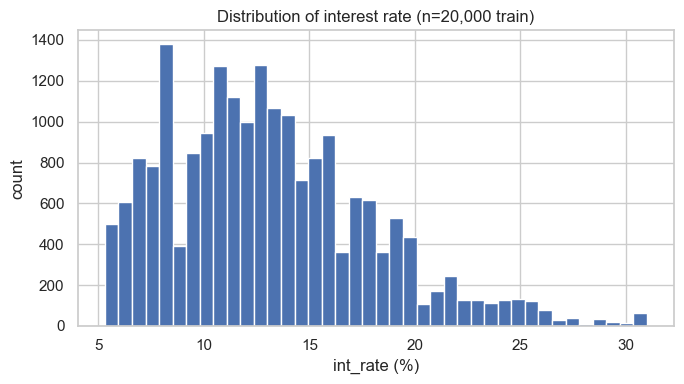

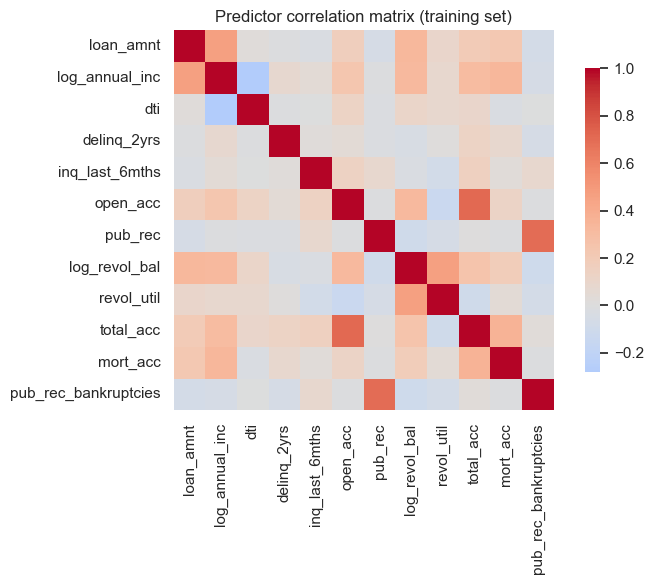

In [20]:

plt.figure(figsize=(7, 4))
plt.hist(train_df[TARGET], bins=40, edgecolor="white")
plt.xlabel("int_rate (%)"); plt.ylabel("count")
plt.title("Distribution of interest rate (n=20,000 train)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Predictor correlation matrix (training set)")
plt.tight_layout(); plt.show()

### EDA Findings

The strongest pairs are `open_acc` ~ `total_acc` with r = 0.715, `pub_rec` ~ `pub_rec_bankruptcies` with r = 0.695, and `log_revol_bal` ~ `revol_util` with r = 0.468. The maximum predictor VIF is 2.51 for `total_acc`; every one of the 12 predictors sits well under 5. The target histogram is unimodal, mildly right-skewed, centered near 12–13% with a thin tail extending to 31%.

An r of 0.715 says the two account-count variables move together strongly but not identically — borrowers with many total accounts tend to have many open ones. A VIF of 2.51 means that predictor's variance is inflated roughly 2.5× relative to orthogonal data, which is mild rather than crippling (VIF < 5 is conventionally considered acceptable). The histogram's spread of about 4.8 is the baseline RMSE for a mean-only predictor.

### 4. Baseline — Full OLS

Every selection or shrinkage method needs a reference point. Full OLS with all 12 predictors and no penalty sets the fit-vs-complexity anchor that forward, backward, PCR, and PLSR must beat or at least simplify.

In [21]:
full_model = sm.OLS(y_train.astype(float), sm.add_constant(X_train.astype(float))).fit()
print(full_model.summary())
test_pred = full_model.predict(sm.add_constant(X_test.astype(float)))
print(f"\nTest RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.4f}")
print(f"Test R2: {r2_score(y_test, test_pred):.4f}")


                            OLS Regression Results                            
Dep. Variable:               int_rate   R-squared:                       0.213
Model:                            OLS   Adj. R-squared:                  0.213
Method:                 Least Squares   F-statistic:                     451.7
Date:                Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                        19:23:22   Log-Likelihood:                -57433.
No. Observations:               20000   AIC:                         1.149e+05
Df Residuals:                   19987   BIC:                         1.150e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   33.4277 

### Full OLS Findings

Training R² is 0.2133 (adjusted 0.2128), F = 451.7 with p ≈ 0, AIC = 114,892.2, BIC = 114,994.9, condition number ≈ 2.18e+06. Test RMSE is 4.2884 and test R² is 0.2091. All 12 slopes are significant at p < 0.05 (the weakest is `pub_rec` at p = 0.036). Key sign patterns: `revol_util` +0.0745 per point, `inq_last_6mths` +1.23 per inquiry, `log_revol_bal` −0.84, `log_annual_inc` −1.78 — so higher income and higher log balances are associated with lower rates.

An R² of 0.213 means roughly 21% of the rate variance is explained — modest, which is expected when the dominant driver (`grade`) is excluded by design. The F-test rejects H₀ (all slopes zero) decisively, but with 20,000 rows almost any signal is "significant", so effect sizes and R² carry more weight than p-values. AIC and BIC are unitless comparison scores that only matter against rival models on the same data. Test RMSE of 4.29 against a target standard deviation of 4.82 is about an 11% improvement over predicting the mean.

The large condition number (≈ 2.18e+06) reflects the fact that the raw feature matrix mixes very different scales — a column of ones, loan amounts in the thousands, log columns around 10, and DTI/`revol_util` as small numbers. That scale spread alone is enough to make the matrix numerically ill-conditioned, which is why statsmodels fires its generic warning. The actual collinearity among predictors is mild — the VIF table confirms it (max 2.51).

### 5. Forward Selection by AIC

With 12 predictors, 2¹² = 4096 subsets could in principle be searched, but that is wasteful. Forward selection builds the model greedily: start empty, add the variable that most improves AIC, and stop when no addition helps. The result is a parsimonious set and an informative ordering showing how each variable earns its place.

Forward selection order (12 selected): ['revol_util', 'inq_last_6mths', 'log_annual_inc', 'loan_amnt', 'log_revol_bal', 'open_acc', 'mort_acc', 'delinq_2yrs', 'pub_rec_bankruptcies', 'total_acc', 'dti', 'pub_rec']
step 1: +revol_util  AIC=118364.5  R2=0.0631  adjR2=0.0631  BIC=118380.3
step 2: +inq_last_6mths  AIC=117344.7  R2=0.1098  adjR2=0.1097  BIC=117368.5
step 3: +log_annual_inc  AIC=116639.7  R2=0.1407  adjR2=0.1406  BIC=116671.3
step 4: +loan_amnt  AIC=115993.6  R2=0.1681  adjR2=0.1680  BIC=116033.1
step 5: +log_revol_bal  AIC=115416.3  R2=0.1919  adjR2=0.1917  BIC=115463.7
step 6: +open_acc  AIC=115240.2  R2=0.1990  adjR2=0.1988  BIC=115295.5
step 7: +mort_acc  AIC=115129.9  R2=0.2035  adjR2=0.2032  BIC=115193.1
step 8: +delinq_2yrs  AIC=115024.0  R2=0.2078  adjR2=0.2075  BIC=115095.1
step 9: +pub_rec_bankruptcies  AIC=114927.7  R2=0.2117  adjR2=0.2113  BIC=115006.8
step 10: +total_acc  AIC=114904.8  R2=0.2127  adjR2=0.2123  BIC=114991.8
step 11: +dti  AIC=114894.6  R2=0.2131 

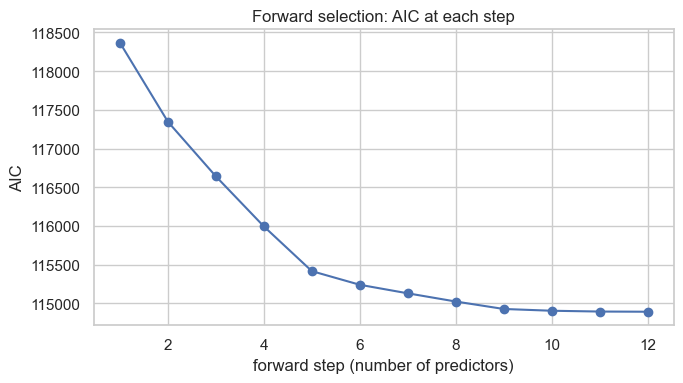

In [22]:
def forward_select(X, y):
    remaining = list(X.columns); selected = []
    cur_aic = np.inf; steps = []
    while remaining:
        best, best_aic, best_m = None, np.inf, None
        for c in remaining:
            m = sm.OLS(y.astype(float), sm.add_constant(X[selected + [c]].astype(float))).fit()
            if m.aic < best_aic:
                best, best_aic, best_m = c, m.aic, m
        if best_aic < cur_aic - 1e-6:
            selected.append(best); remaining.remove(best); cur_aic = best_aic
            steps.append({"added": best, "aic": best_m.aic, "r2": best_m.rsquared,
                          "adjr2": best_m.rsquared_adj, "bic": best_m.bic, "n": len(selected)})
        else:
            break
    return selected, steps

fwd_vars, fwd_steps = forward_select(X_train, y_train)
print(f"Forward selection order ({len(fwd_vars)} selected): {fwd_vars}")
for s in fwd_steps:
    print(f"step {s['n']}: +{s['added']}  AIC={s['aic']:.1f}  R2={s['r2']:.4f}  adjR2={s['adjr2']:.4f}  BIC={s['bic']:.1f}")
fwd_model = sm.OLS(y_train.astype(float), sm.add_constant(X_train[fwd_vars].astype(float))).fit()
fwd_pred = fwd_model.predict(sm.add_constant(X_test[fwd_vars].astype(float)))
print(f"\nFinal forward model: AIC={fwd_model.aic:.1f} BIC={fwd_model.bic:.1f} train R2={fwd_model.rsquared:.4f} "
      f"test RMSE={np.sqrt(mean_squared_error(y_test, fwd_pred)):.4f} test R2={r2_score(y_test, fwd_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.plot([s["n"] for s in fwd_steps], [s["aic"] for s in fwd_steps], marker="o")
plt.xlabel("forward step (number of predictors)"); plt.ylabel("AIC")
plt.title("Forward selection: AIC at each step"); plt.tight_layout(); plt.show()


### Forward Selection Findings

Forward selection kept all 12 predictors in order: `revol_util` → `inq_last_6mths` → `log_annual_inc` → `loan_amnt` → `log_revol_bal` → `open_acc` → `mort_acc` → `delinq_2yrs` → `pub_rec_bankruptcies` → `total_acc` → `dti` → `pub_rec`. AIC fell from 118,364.5 with one variable to 114,892.2 with twelve. The first variable alone gives R² = 0.0631; the full path reaches R² = 0.2133. Final test RMSE is 4.2884 and test R² is 0.2091 — identical to full OLS.

The entry order ranks marginal AIC contribution. Revolving utilization enters first because it carries the strongest solo signal (R² of 0.063 on its own). Payment-history and income follow. Late-step AIC drops are tiny — `dti` improves AIC by 10.2 and `pub_rec` by only 2.4 — real by the AIC ledger but practically negligible. The AIC curve drops steeply at first and then flattens, which is classic diminishing returns.

No variable is dead weight by AIC's standard; even the weakest (`pub_rec`) pays its 2-point complexity charge. Forward search here validates the full set rather than shrinking it.

### 6. Backward Elimination and Selection Comparison

Backward elimination starts with the full 12-variable model and removes the single variable whose removal most lowers AIC, repeating until no further removal helps. If forward and backward arrive at the same model, that is strong evidence the model is stable.

In [23]:
def backward_select(X, y):
    selected = list(X.columns); cur = sm.OLS(y.astype(float), sm.add_constant(X[selected].astype(float))).fit()
    cur_aic = cur.aic; log = [f"start (12 vars): AIC={cur_aic:.1f}"]
    improved = True
    while improved and len(selected) > 1:
        improved = False; best, best_aic, best_m = None, np.inf, None
        for c in selected:
            cols = [x for x in selected if x != c]
            m = sm.OLS(y.astype(float), sm.add_constant(X[cols].astype(float))).fit()
            if m.aic < best_aic:
                best, best_aic, best_m = c, m.aic, m
        if best_aic < cur_aic - 1e-6:
            selected.remove(best); cur_aic = best_aic; cur = best_m; improved = True
            log.append(f"removed {best}: AIC={cur_aic:.1f} R2={cur.rsquared:.4f}")
    return selected, cur, log

bwd_vars, bwd_model, bwd_log = backward_select(X_train, y_train)
print(f"Backward elimination kept {len(bwd_vars)} predictors: {bwd_vars}")
print("\n".join(bwd_log))
for name, cols, m in [("Full OLS", PREDICTORS, full_model), ("Forward", fwd_vars, fwd_model), ("Backward", bwd_vars, bwd_model)]:
    pr = m.predict(sm.add_constant(X_test[cols].astype(float)))
    print(f"{name}: AIC={m.aic:.1f} BIC={m.bic:.1f} testRMSE={np.sqrt(mean_squared_error(y_test, pr)):.4f} testR2={r2_score(y_test, pr):.4f}")


Backward elimination kept 12 predictors: ['loan_amnt', 'log_annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'log_revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']
start (12 vars): AIC=114892.2
Full OLS: AIC=114892.2 BIC=114994.9 testRMSE=4.2884 testR2=0.2091
Forward: AIC=114892.2 BIC=114994.9 testRMSE=4.2884 testR2=0.2091
Backward: AIC=114892.2 BIC=114994.9 testRMSE=4.2884 testR2=0.2091


### Backward Elimination Findings

Backward elimination removed nothing. Starting AIC is 114,892.2 and ending AIC is 114,892.2; all 12 variables stay. The three-row verdict is unanimous:

| Method | AIC | Test RMSE | Test R² |
|---|---|---|---|
| Full OLS | 114,892.2 | 4.2884 | 0.2091 |
| Forward | 114,892.2 | 4.2884 | 0.2091 |
| Backward | 114,892.2 | 4.2884 | 0.2091 |

Both search directions agree exactly. The 12-variable set is AIC-stable, and subsetting buys zero generalization gain on this dataset. Differences would need to exceed about 0.01 RMSE to matter in practice; here they are zero to four decimals.

### 7. Principal Components Regression (PCR)

Predictors in this dataset share latent credit "blocks" (account counts, utilization). PCR compresses the 12 correlated predictors into fewer uncorrelated principal components, then regresses the target on those components. It stabilizes coefficients and tests whether fewer dimensions predict just as well.

Here PCR is tuned by 5-fold cross-validation across k = 1 to 12 components.

k=1: CV MSE=23.1977 +- 0.4962
k=2: CV MSE=23.1964 +- 0.4948
k=3: CV MSE=23.0713 +- 0.5429
k=4: CV MSE=22.3109 +- 0.6186
k=5: CV MSE=21.9859 +- 0.5468
k=6: CV MSE=20.9372 +- 0.5887
k=7: CV MSE=20.8670 +- 0.5982
k=8: CV MSE=20.3670 +- 0.5927
k=9: CV MSE=19.7594 +- 0.4924
k=10: CV MSE=18.5968 +- 0.3687
k=11: CV MSE=18.5863 +- 0.3564
k=12: CV MSE=18.3299 +- 0.3010

Best k=12 (lowest CV MSE=18.3299)
Variance ratios: [0.2162, 0.1507, 0.1191, 0.1093, 0.0845, 0.0779, 0.0683, 0.0645, 0.0336, 0.0322, 0.0251, 0.0186]
Cumulative: [0.2162, 0.3670, 0.4861, 0.5954, 0.6799, 0.7578, 0.8260, 0.8905, 0.9240, 0.9563, 0.9814, 1.0000]
PCR(k=12) test RMSE=4.2884 test R2=0.2091


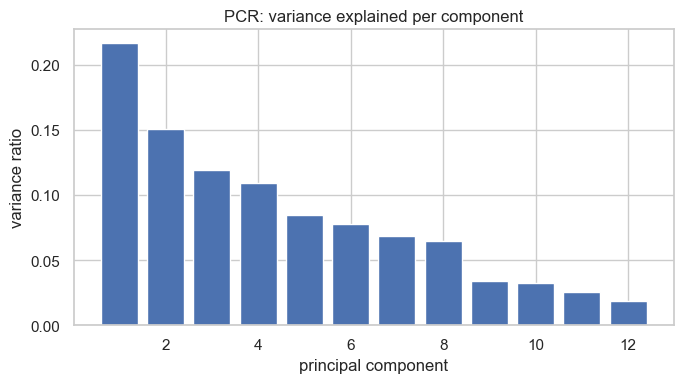

In [27]:
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train); Xte_s = scaler.transform(X_test)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
pcr_cv = []
for k in range(1, len(PREDICTORS) + 1):
    pipe = make_pipeline(PCA(n_components=k), LinearRegression())
    s = -cross_val_score(pipe, Xtr_s, y_train, cv=kf, scoring="neg_mean_squared_error")
    pcr_cv.append((k, float(s.mean()), float(s.std())))
    print(f"k={k}: CV MSE={s.mean():.4f} +- {s.std():.4f}")
best_k = min(pcr_cv, key=lambda t: t[1])[0]
print(f"\nBest k={best_k} (lowest CV MSE={min(m for _, m, _ in pcr_cv):.4f})")
pca_full = PCA().fit(Xtr_s)
print("Variance ratios: [" + ", ".join(f"{v:.4f}" for v in pca_full.explained_variance_ratio_) + "]")
print("Cumulative: [" + ", ".join(f"{v:.4f}" for v in np.cumsum(pca_full.explained_variance_ratio_)) + "]")
pcr = make_pipeline(PCA(n_components=best_k), LinearRegression())
pcr.fit(Xtr_s, y_train)
pcr_pred = pcr.predict(Xte_s)
print(f"PCR(k={best_k}) test RMSE={np.sqrt(mean_squared_error(y_test, pcr_pred)):.4f} test R2={r2_score(y_test, pcr_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.bar(range(1, len(PREDICTORS)+1), pca_full.explained_variance_ratio_)
plt.xlabel("principal component"); plt.ylabel("variance ratio")
plt.title("PCR: variance explained per component"); plt.tight_layout(); plt.show()


### PCR Findings

Cross-validated MSE falls from 23.1977 at k = 1 to 18.3299 at k = 12. k = 11 gives 18.5863 ± 0.3564, which is inside k = 12's noise band. Variance ratios: PC1 explains 21.6% of the X variance, the first four PCs together explain 59.5%, the first eight explain 89.1%, and all twelve sum to 1.0000. PCR with k = 12 yields a test RMSE of 4.2884 and R² of 0.2091, identical to OLS to four decimals.

A CV MSE ± standard deviation gives both the mean estimate of out-of-sample error and its fold-to-fold wobble — k = 11 versus k = 12 differ by about 0.26, which sits within noise. The scree bars show that variance is spread across many directions (no dominant PC), so PCR needs nearly all components to reconstruct X. Test RMSE identical to OLS is mathematically expected when k equals the full feature count.

PCR confirms that the signal here is diffuse across many small-variance directions — compressing to few components (k ≤ 8 pushes CV MSE above 20.37) clearly hurts. PCR's value on this dataset is diagnostic (a stability check), not predictive gain.

### 8. Partial Least Squares Regression (PLSR)

PCR wastes components on high-variance-but-irrelevant X directions. PLSR instead builds components that maximize covariance with the target, so it often matches OLS accuracy with fewer, more predictive components. This step is the fair head-to-head for "rotation vs selection".

k=1: CV MSE=19.3931 +- 0.6711
k=2: CV MSE=18.7868 +- 0.4329
k=3: CV MSE=18.4321 +- 0.3358
k=4: CV MSE=18.3486 +- 0.3125
k=5: CV MSE=18.3375 +- 0.3041
k=6: CV MSE=18.3313 +- 0.3030
k=7: CV MSE=18.3297 +- 0.3014
k=8: CV MSE=18.3301 +- 0.3010
k=9: CV MSE=18.3300 +- 0.3009
k=10: CV MSE=18.3299 +- 0.3010
k=11: CV MSE=18.3299 +- 0.3010
k=12: CV MSE=18.3299 +- 0.3010

Best k=7 (lowest CV MSE=18.3297)
PLS(k=7) test RMSE=4.2888 test R2=0.2090


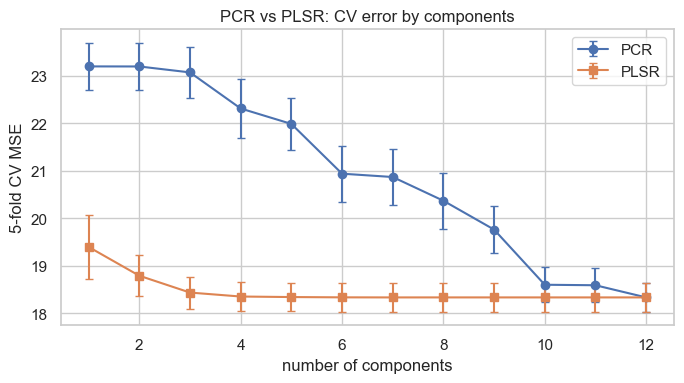

In [25]:
pls_cv = []
for k in range(1, len(PREDICTORS) + 1):
    pls_m = PLSRegression(n_components=k)
    s = -cross_val_score(pls_m, Xtr_s, y_train, cv=kf, scoring="neg_mean_squared_error")
    pls_cv.append((k, float(s.mean()), float(s.std())))
    print(f"k={k}: CV MSE={s.mean():.4f} +- {s.std():.4f}")
pls_k = min(pls_cv, key=lambda t: t[1])[0]
print(f"\nBest k={pls_k} (lowest CV MSE={min(m for _, m, _ in pls_cv):.4f})")
pls = PLSRegression(n_components=pls_k); pls.fit(Xtr_s, y_train)
pls_pred = pls.predict(Xte_s).ravel()
print(f"PLS(k={pls_k}) test RMSE={np.sqrt(mean_squared_error(y_test, pls_pred)):.4f} test R2={r2_score(y_test, pls_pred):.4f}")

plt.figure(figsize=(7, 4))
plt.errorbar([k for k, _, _ in pcr_cv], [m for _, m, _ in pcr_cv], yerr=[s for _, _, s in pcr_cv], marker="o", capsize=3, label="PCR")
plt.errorbar([k for k, _, _ in pls_cv], [m for _, m, _ in pls_cv], yerr=[s for _, _, s in pls_cv], marker="s", capsize=3, label="PLSR")
plt.xlabel("number of components"); plt.ylabel("5-fold CV MSE")
plt.title("PCR vs PLSR: CV error by components"); plt.legend(); plt.tight_layout(); plt.show()


### PLSR Findings

PLS CV MSE: k = 1 is 19.3931, k = 2 is 18.7868, k = 4 is 18.3486, and the optimum at k = 7 is 18.3297 ± 0.3014; k = 8 to 12 all sit around 18.33. Test RMSE is 4.2888 and R² is 0.2090 — essentially tied with OLS and PCR (4.2884) and far below PCR's small-k errors (PCR at k = 1 is 23.20).

The curve's elbow at k ≈ 4–5 (CV MSE ≈ 18.34) shows that PLS extracts nearly all the predictive variance in about five directions, while PCR needs ten or more. The flat tail means extra components add nothing, which is cross-validation correctly stopping early. The ± 0.30 standard deviations overlap from k ≈ 5 upward, so k = 7 versus k = 5 is a judgment call within noise rather than a sharp peak.

Supervised compression wins on parsimony: PLS with k = 7 matches full-model accuracy with about 40% fewer dimensions. The predictive difference versus OLS is trivial in absolute terms (roughly 0.000 RMSE), so the prize is simplicity and stability, not accuracy.

### 9. Final Comparison on the Held-Out Test Set

Every method fit above is compared on the same held-out test set, together with RidgeCV, LassoCV, and ElasticNetCV reference fits. The RMSE bar chart and a PLS predicted-vs-actual scatter summarize the result.

What to look for: how tight the bar chart is (likely near-tie), the chosen alphas for ridge/lasso/elastic net, whether any L1 model drops variables, and the shape of the scatter.

FINAL TEST COMPARISON (test n=5000):
Full OLS     RMSE=4.2884 R2=0.2091
Forward      RMSE=4.2884 R2=0.2091
Backward     RMSE=4.2884 R2=0.2091
PCR(k=12)    RMSE=4.2884 R2=0.2091
PLS(k=7)     RMSE=4.2888 R2=0.2090
Ridge        RMSE=4.2884 R2=0.2091
Lasso        RMSE=4.2885 R2=0.2090
ElNet        RMSE=4.2885 R2=0.2090

Ridge alpha=47.15 | Lasso alpha=0.002024 nz=12 | ElasticNet alpha=0.002212 l1=0.8 nz=12


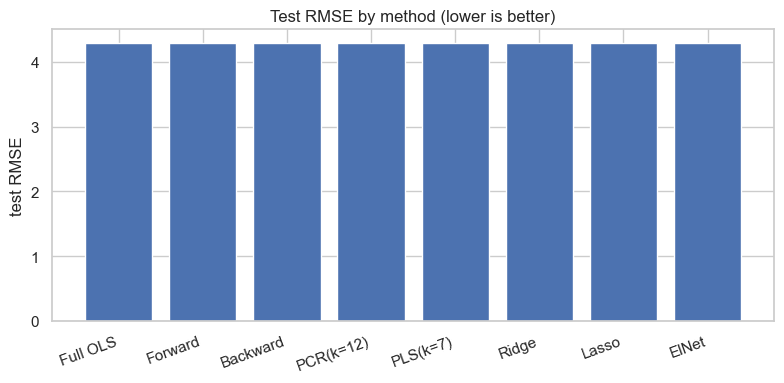

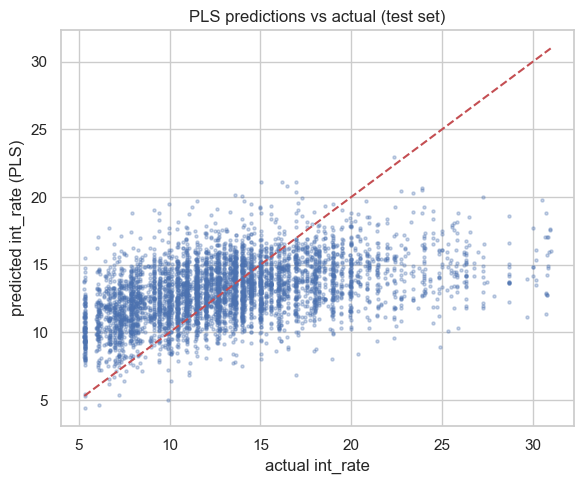

In [26]:
ridge = RidgeCV(alphas=np.logspace(-2, 4, 50), cv=kf).fit(Xtr_s, y_train)
lasso = LassoCV(alphas=np.logspace(-3, 2, 50), cv=5, random_state=42, max_iter=5000).fit(Xtr_s, y_train)
en = ElasticNetCV(alphas=np.logspace(-3, 2, 30), l1_ratio=[0.2, 0.5, 0.8], cv=5, random_state=42, max_iter=5000).fit(Xtr_s, y_train)
results = []
for name, pr in [("Full OLS", test_pred), ("Forward", fwd_pred), ("Backward", bwd_model.predict(sm.add_constant(X_test[bwd_vars].astype(float)))),
                 (f"PCR(k={best_k})", pcr_pred), (f"PLS(k={pls_k})", pls_pred),
                 ("Ridge", ridge.predict(Xte_s)), ("Lasso", lasso.predict(Xte_s)), ("ElNet", en.predict(Xte_s))]:
    results.append((name, float(np.sqrt(mean_squared_error(y_test, pr))), float(r2_score(y_test, pr))))
print(f"FINAL TEST COMPARISON (test n={len(y_test)}):")
for name, rm, r2 in results:
    print(f"{name:12s} RMSE={rm:.4f} R2={r2:.4f}")
print(f"\nRidge alpha={ridge.alpha_:.2f} | Lasso alpha={float(lasso.alpha_):.6f} nz={int((lasso.coef_ != 0).sum())} | ElasticNet alpha={float(en.alpha_):.6f} l1={en.l1_ratio_} nz={int((en.coef_ != 0).sum())}")

plt.figure(figsize=(8, 4))
plt.bar([n for n, _, _ in results], [rm for _, rm, _ in results])
plt.ylabel("test RMSE"); plt.title("Test RMSE by method (lower is better)")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(y_test, pls_pred, s=5, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("actual int_rate"); plt.ylabel("predicted int_rate (PLS)")
plt.title("PLS predictions vs actual (test set)"); plt.tight_layout(); plt.show()


### Final Comparison Findings

Test RMSE spans 4.2884 to 4.2888 across all eight methods — Full OLS 4.2884, Forward 4.2884, Backward 4.2884, PCR(k=12) 4.2884, PLS(k=7) 4.2888, Ridge 4.2884 (α = 47.15), Lasso 4.2885 (α = 0.002024, 12/12 non-zero), ElasticNet 4.2885 (α = 0.002212, l1 = 0.8, 12/12 non-zero). R² ≈ 0.209 everywhere. The scatter hugs the diagonal at low rates and fans out above about 20%, which reflects heterogeneous high-rate loans.

A 0.001 RMSE band across eight methods means no predictive winner — the test mean's own noise (about 0.06) dwarfs these gaps. Lasso and elastic net keeping all 12 variables (non-zero count 12) independently confirms the selection verdict: nothing deserves zeroing, and the CV-chosen alphas are tiny (near-OLS). Ridge's α ≈ 47 is mild shrinkage on the standardized scale — again near-OLS.

The practical conclusion is three-pointed. For interpretation, the 12-variable OLS or backward model is the right one to report (all p < 0.05, VIFs under 3). For a parsimonious predictor, PLS with k = 7 ties the error with fewer dimensions and more stable coefficients under the account-count and utilization blocks. Ridge remains a sensible fallback if future data grows more collinear. No method should be claimed to "beat" the others on accuracy — they tie.

Twelve ordinary credit facts explain about 21% of a loan's rate; every shortlisting method agrees that none can be dropped; squeezing with PCR needs all 12 blends; smart squeezing with PLS needs only 7 blends for the same error. **Selection, rotation, and shrinkage answer different questions — which variables? which blends? how much shrinkage? — and here all three agree that the signal is real, diffuse, and honest.** The main limitation is that without `grade`, the R² ceiling is low by construction; these are associations, not causal effects.

## Part C — Taiwan Credit Card: Selection, PCR, and PLSR

On Lending Club every method tied (test RMSE 4.2884 to 4.2888) because the 12 predictors were only mildly correlated (max VIF 2.51). Methods built for correlated predictors can only show their value where correlation exists.

Taiwan's six monthly bills and six payment-status variables are strongly correlated, so this is the fair test. The target is `log_LIMIT_BAL`. The `forward_select` and `backward_select` functions defined earlier are reused.

### 10. Taiwan Design Matrix, Train/Test Split, and VIF

Selection and PCR/PLS both need a single clean numeric matrix. VIF quantifies how redundant each predictor is (VIF > 10 is a serious concern, VIF > 5 is worth checking).

The 25 predictors are `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`, plus one-hot `SEX`, `EDUCATION`, and `MARRIAGE` (first level dropped). The split is 80/20 stratified by default status with seed 42. VIF is computed on the training set only.

In [21]:
TW_X = ["AGE"] + [f"PAY_{i}" for i in range(1, 7)] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
Xtw = pd.get_dummies(tw[TW_X + ["SEX", "EDUCATION", "MARRIAGE"]], columns=["SEX", "EDUCATION", "MARRIAGE"], drop_first=True).astype(float)
ytw = tw["log_LIMIT_BAL"]
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(Xtw, ytw, test_size=0.2, random_state=42, stratify=tw["default"])
TW_PRED = list(Xtw.columns)
Xv = sm.add_constant(Xtw_tr)
tw_vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=TW_PRED).sort_values(ascending=False)
print(f"Train {Xtw_tr.shape}, Test {Xtw_te.shape}; predictors = {len(TW_PRED)}")
print(f"VIF > 10: {(tw_vif > 10).sum()} | VIF > 5: {(tw_vif > 5).sum()} | max VIF = {tw_vif.max():.2f}")
print(tw_vif.head(12).round(2).to_string())

Train (23972, 25), Test (5993, 25); predictors = 25
VIF > 10: 0 | VIF > 5: 10 | max VIF = 7.06
PAY_5            7.06
PAY_4            6.58
log_BILL_AMT3    6.10
log_BILL_AMT4    5.93
PAY_3            5.90
log_BILL_AMT5    5.80
log_BILL_AMT2    5.77
log_BILL_AMT6    5.71
PAY_2            5.48
PAY_6            5.17
log_PAY_AMT2     3.82
log_PAY_AMT1     3.74


### Taiwan VIF Findings

* Training 23,972 × 25, test 5,993 × 25.
* 10 predictors have VIF > 5, and none exceed 10. The maximum is 7.06 for `PAY_5`.
* The high values are all payment-status months (`PAY_2–PAY_6`, VIF 5.2 to 7.1) and bill months (`log_BILL_AMT2–6`, VIF 5.7 to 6.1).

This is moderate, structured collinearity. Taiwan has much more collinearity than Lending Club (max 2.51 there), but after log-transforming the bills it is moderate rather than severe (the raw bills were correlated at 0.80 to 0.95).

The collinearity sits in two blocks, which is the month-to-month persistence of the same borrower behaviour — paying late and carrying a balance tend to persist. This is exactly the kind of redundancy that PCR and PLS compress.

VIF measures redundancy, not predictive value, so the collinear predictors cannot be dismissed as useless.

### 11. Taiwan — Full OLS, Forward Selection, and Backward Elimination by AIC

Stepwise selection asks whether a subset of the 25 predictors fits as well as all of them. AIC rewards fit and penalizes each extra parameter by 2 (lower is better). Forward starts empty and adds; backward starts full and removes.

Forward order (23 kept): ['PAY_2', 'log_PAY_AMT6', 'PAY_4', 'EDUCATION_3', 'EDUCATION_2', 'AGE', 'log_PAY_AMT5', 'MARRIAGE_2', 'MARRIAGE_3', 'SEX_2'] ...
  step 1: +PAY_2           AIC=62661.9 adjR2=0.1017
  step 2: +log_PAY_AMT6    AIC=61079.6 adjR2=0.1591
  step 3: +PAY_4           AIC=60582.1 adjR2=0.1764
  step 4: +EDUCATION_3     AIC=60173.7 adjR2=0.1903
  step 5: +EDUCATION_2     AIC=59273.4 adjR2=0.2202
  step 6: +AGE             AIC=58564.5 adjR2=0.2430
Backward kept 23; removed: ['log_BILL_AMT2', 'log_BILL_AMT3']


,model,n_pred,AIC,BIC,test_RMSE,test_R2
0,Full OLS,25,57542.7958,57752.9965,0.7937,0.2769
1,Forward,23,57539.1546,57733.1860,0.7937,0.2768
2,Backward,23,57539.1546,57733.1860,0.7937,0.2768


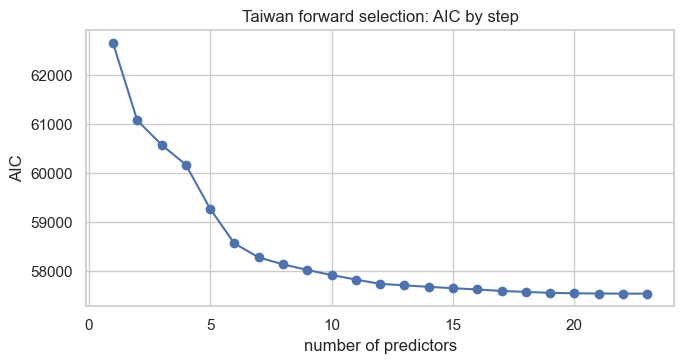

In [22]:
tw_full = sm.OLS(ytw_tr, sm.add_constant(Xtw_tr)).fit()
tw_fwd_vars, tw_fwd_steps = forward_select(Xtw_tr, ytw_tr)
tw_bwd_vars, tw_bwd_model, tw_bwd_log = backward_select(Xtw_tr, ytw_tr)
tw_fwd_model = sm.OLS(ytw_tr, sm.add_constant(Xtw_tr[tw_fwd_vars])).fit()
print(f"Forward order ({len(tw_fwd_vars)} kept): {tw_fwd_vars[:10]} ...")
for s in tw_fwd_steps[:6]:
    print(f"  step {s['n']}: +{s['added']:15s} AIC={s['aic']:.1f} adjR2={s['adjr2']:.4f}")
print(f"Backward kept {len(tw_bwd_vars)}; removed: {sorted(set(TW_PRED) - set(tw_bwd_vars))}")
tw_rows = []
for name, cols, m in [("Full OLS", TW_PRED, tw_full), ("Forward", tw_fwd_vars, tw_fwd_model), ("Backward", tw_bwd_vars, tw_bwd_model)]:
    pr = m.predict(sm.add_constant(Xtw_te[cols], has_constant="add"))
    tw_rows.append((name, len(cols), m.aic, m.bic, np.sqrt(mean_squared_error(ytw_te, pr)), r2_score(ytw_te, pr)))
display(pd.DataFrame(tw_rows, columns=["model", "n_pred", "AIC", "BIC", "test_RMSE", "test_R2"]).round(4))
plt.figure(figsize=(7, 3.8)); plt.plot([s["n"] for s in tw_fwd_steps], [s["aic"] for s in tw_fwd_steps], marker="o")
plt.xlabel("number of predictors"); plt.ylabel("AIC"); plt.title("Taiwan forward selection: AIC by step"); plt.tight_layout(); plt.show()

### Taiwan Stepwise Selection Findings

Forward order: `PAY_2` enters first (adjusted R² 0.1017 alone), then `log_PAY_AMT6` (0.1591), `PAY_4`, `EDUCATION_3`, `EDUCATION_2`, and `AGE` (0.2430 after six steps).

Forward keeps 23 of 25 predictors. Backward removes exactly `log_BILL_AMT2` and `log_BILL_AMT3` and arrives at the same 23-variable model. Final AIC is 57,539.2 for both, compared with 57,542.8 for the full model — a 3.6-point gap, which is small; AIC has no absolute "good" value and is only meaningful relative to other models. Test RMSE is 0.7937 for all three methods, with test R² of 0.277.

Both search directions agree, and they drop two middle bill months, which are the most redundant members of the collinear block. Prediction is unchanged, so selection simplifies the model by two variables without losing any accuracy. The AIC path flattens after about ten steps, which means that most of the explainable variation comes from repayment status, recent payments, education, and age.

The dropped bills are not without a relationship to the limit; they are redundant given `BILL_AMT1` and the other months.

### 12. Taiwan — PCR and PLSR, Tuned by 5-Fold CV

PCR replaces the 25 correlated predictors with k uncorrelated principal components (directions of maximum X variance), then regresses the target on them. It ignores y when building components.

PLSR builds components that maximize covariance with y, so it usually needs fewer components.

Comparing cross-validated MSE for k = 1 to 25 shows how many dimensions the predictive signal actually occupies.

PCR best k=22 (CV MSE 0.6459); first k within 1% of OLS CV MSE: 16
PLS best k=7 (CV MSE 0.6461); first k within 1% of OLS CV MSE: 3
PCA cumulative variance, first 6 PCs: [0.3285, 0.4637, 0.5313, 0.583, 0.63, 0.6708]
  k=1: PCR CV MSE=0.8828  PLS CV MSE=0.7090
  k=3: PCR CV MSE=0.7183  PLS CV MSE=0.6514
  k=6: PCR CV MSE=0.7127  PLS CV MSE=0.6462


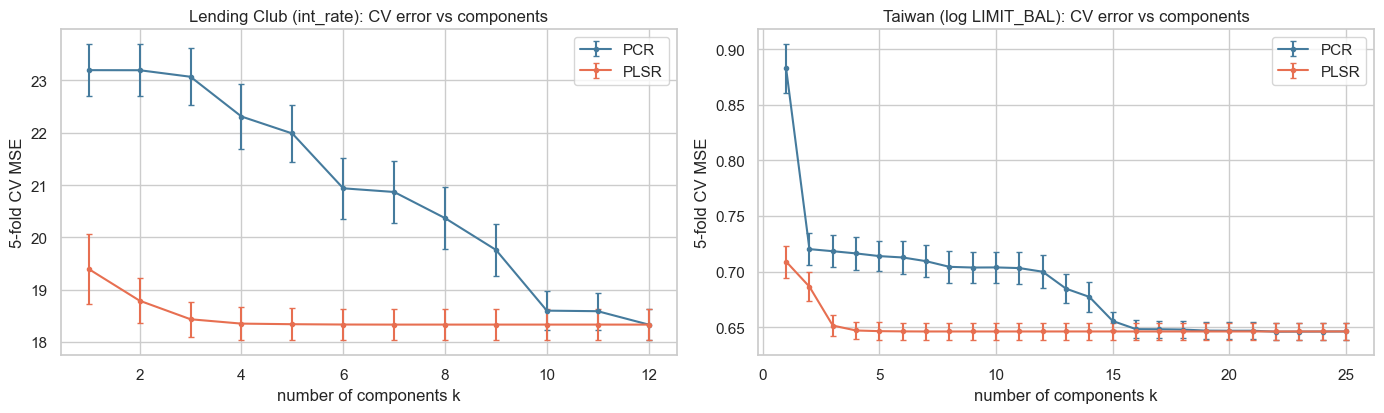

In [23]:
sc_tw = StandardScaler().fit(Xtw_tr)
Ztw_tr, Ztw_te = sc_tw.transform(Xtw_tr), sc_tw.transform(Xtw_te)
P = Ztw_tr.shape[1]
tw_pcr_cv, tw_pls_cv = [], []
for k in range(1, P + 1):
    s1 = -cross_val_score(make_pipeline(PCA(n_components=k), LinearRegression()), Ztw_tr, ytw_tr, cv=kf, scoring="neg_mean_squared_error")
    s2 = -cross_val_score(PLSRegression(n_components=k), Ztw_tr, ytw_tr, cv=kf, scoring="neg_mean_squared_error")
    tw_pcr_cv.append((k, s1.mean(), s1.std())); tw_pls_cv.append((k, s2.mean(), s2.std()))
pcr_k = min(tw_pcr_cv, key=lambda r: r[1])[0]; pls_k2 = min(tw_pls_cv, key=lambda r: r[1])[0]
ols_cv = tw_pcr_cv[-1][1]
pcr_95 = next(k for k, m, s in tw_pcr_cv if m <= ols_cv * 1.01)
pls_95 = next(k for k, m, s in tw_pls_cv if m <= ols_cv * 1.01)
print(f"PCR best k={pcr_k} (CV MSE {min(r[1] for r in tw_pcr_cv):.4f}); first k within 1% of OLS CV MSE: {pcr_95}")
print(f"PLS best k={pls_k2} (CV MSE {min(r[1] for r in tw_pls_cv):.4f}); first k within 1% of OLS CV MSE: {pls_95}")
pv = PCA().fit(Ztw_tr).explained_variance_ratio_
print("PCA cumulative variance, first 6 PCs:", np.round(np.cumsum(pv)[:6], 4).tolist())
for k, label in [(1, "k=1"), (3, "k=3"), (6, "k=6")]:
    print(f"  {label}: PCR CV MSE={tw_pcr_cv[k-1][1]:.4f}  PLS CV MSE={tw_pls_cv[k-1][1]:.4f}")
tw_pcr = make_pipeline(PCA(n_components=pcr_95), LinearRegression()).fit(Ztw_tr, ytw_tr)
tw_pls = PLSRegression(n_components=pls_95).fit(Ztw_tr, ytw_tr)
for name, m in [(f"PCR(k={pcr_95})", tw_pcr), (f"PLS(k={pls_95})", tw_pls)]:
    pr = np.ravel(m.predict(Ztw_te))
    tw_rows.append((name, int(name.split("=")[1][:-1]), np.nan, np.nan, np.sqrt(mean_squared_error(ytw_te, pr)), r2_score(ytw_te, pr)))

FIG = "../../../week_10092026_w7/DX799O1/figures"; os.makedirs(FIG, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for a_, cvs, title in [(ax[0], (pcr_cv, pls_cv), "Lending Club (int_rate)"), (ax[1], (tw_pcr_cv, tw_pls_cv), "Taiwan (log LIMIT_BAL)")]:
    for res, lab, col in [(cvs[0], "PCR", "#457b9d"), (cvs[1], "PLSR", "#e76f51")]:
        a_.errorbar([r[0] for r in res], [r[1] for r in res], yerr=[r[2] for r in res], marker="o", ms=3, capsize=2, label=lab, color=col)
    a_.set_xlabel("number of components k"); a_.set_ylabel("5-fold CV MSE"); a_.set_title(f"{title}: CV error vs components"); a_.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w3_pcr_pls_cv.png", dpi=150, bbox_inches="tight"); plt.show()

### Taiwan PCR vs PLSR Findings

| Taiwan | k = 1 | k = 3 | k = 6 | Best k (CV MSE) | First k within 1% of OLS |
|---|---|---|---|---|---|
| PCR | 0.8828 | 0.7183 | 0.7127 | 22 (0.6459) | **16** |
| PLSR | 0.7090 | 0.6514 | 0.6462 | 7 (0.6461) | **3** |

The first principal component explains 32.9% of X variance, and six components explain 67.1%. In the plots, the left panel (Lending Club) shows PCR needing nearly all 12 components while PLS flattens by about k = 4. The right panel (Taiwan) shows the same pattern more sharply.

The key learning point is that PLS uses y and PCR does not. PCR's first components capture the biggest X patterns (the correlated bill and payment-status blocks), which turn out to be only weakly related to the credit limit. PCR needs 16 of 25 components to come within 1% of OLS. PLS builds components aimed at y and gets there with 3, an 8-fold compression.

Neither method beats OLS on accuracy. The best CV MSEs (0.6459 and 0.6461) match OLS. With 24,000 rows, the estimation variance is already small, so the benefit of dimension reduction here is a compact representation, not lower error.

### 13. Taiwan Final Comparison (plus Ridge and Lasso) and Cross-Dataset Summary

Every method from this analysis is put on the same Taiwan test set and compared, with ridge and lasso added as reference fits. Taiwan is then lined up against Lending Club in one summary table, to see where each method's advantage appears.

In [24]:
tw_ridge = RidgeCV(alphas=np.logspace(-2, 4, 50), cv=kf).fit(Ztw_tr, ytw_tr)
tw_lasso = LassoCV(alphas=np.logspace(-4, 1, 50), cv=5, random_state=42, max_iter=10000).fit(Ztw_tr, ytw_tr)
for name, m in [(f"Ridge(a={tw_ridge.alpha_:.2f})", tw_ridge), (f"Lasso(a={tw_lasso.alpha_:.4f})", tw_lasso)]:
    pr = m.predict(Ztw_te)
    tw_rows.append((name, int((np.abs(m.coef_) > 1e-10).sum()), np.nan, np.nan, np.sqrt(mean_squared_error(ytw_te, pr)), r2_score(ytw_te, pr)))
tw_tab = pd.DataFrame(tw_rows, columns=["model", "n_pred_or_k", "AIC", "BIC", "test_RMSE", "test_R2"])
display(tw_tab.round(4))
lc_tab = pd.DataFrame([(n_, rm, r2) for n_, rm, r2 in results], columns=["model", "test_RMSE", "test_R2"])
cross = pd.concat([lc_tab.assign(dataset="Lending Club int_rate"), tw_tab[["model", "test_RMSE", "test_R2"]].assign(dataset="Taiwan log LIMIT_BAL")])
display(cross[["dataset", "model", "test_RMSE", "test_R2"]].round(4))

,model,n_pred_or_k,AIC,BIC,test_RMSE,test_R2
0,Full OLS,25,57542.7958,57752.9965,0.7937,0.2769
1,Forward,23,57539.1546,57733.1860,0.7937,0.2768
2,Backward,23,57539.1546,57733.1860,0.7937,0.2768
3,PCR(k=16),16,NaN,NaN,0.7948,0.2748
4,PLS(k=3),3,NaN,NaN,0.7964,0.2718
5,Ridge(a=193.07),25,NaN,NaN,0.7936,0.2770
6,Lasso(a=0.0005),25,NaN,NaN,0.7936,0.2770


,dataset,model,test_RMSE,test_R2
0,Lending Club int_rate,Full OLS,4.2884,0.2091
1,Lending Club int_rate,Forward,4.2884,0.2091
2,Lending Club int_rate,Backward,4.2884,0.2091
3,Lending Club int_rate,PCR(k=12),4.2884,0.2091
4,Lending Club int_rate,PLS(k=7),4.2888,0.2090
5,Lending Club int_rate,Ridge,4.2884,0.2091
6,Lending Club int_rate,Lasso,4.2885,0.2090
7,Lending Club int_rate,ElNet,4.2885,0.2090
0,Taiwan log LIMIT_BAL,Full OLS,0.7937,0.2769
1,Taiwan log LIMIT_BAL,Forward,0.7937,0.2768


### Taiwan Final Comparison Findings

Taiwan test RMSE:

* Full OLS 0.7937
* Forward / Backward 0.7937 (23 predictors)
* PCR(k = 16) 0.7948
* PLS(k = 3) 0.7964
* Ridge (α = 193) **0.7936**
* Lasso (α = 0.0005) **0.7936**

The spread is 0.0028 log units. Lending Club's spread is 0.0004 (4.2884 to 4.2888).

Every method lands at the same accuracy on both datasets. The ceiling is set by the information in the features, not by how the linear model is estimated.

The methods differ in the simplicity they buy:

* Stepwise drops two bill months.
* PLS compresses 25 predictors into three components for a 0.3% RMSE cost.
* Lasso keeps all 25 predictors at this α.

Linear models leave a lot unexplained. Test R² is about 0.21 for Lending Club (without `grade`) and 0.28 for Taiwan, so substantial variation remains that any linear specification cannot reach.

The methods are not interchangeable in every setting; regularization can still matter when data is scarce or when the feature set is wider.

### 14. Cross-Dataset Summary

A short numeric summary of the best test RMSE, the spread across methods for each dataset, and the number of components PCR and PLS need to come within 1% of OLS on Taiwan.

In [25]:
print("Lending Club best test RMSE:", round(lc_tab.test_RMSE.min(), 4), "| spread across methods:", round(lc_tab.test_RMSE.max() - lc_tab.test_RMSE.min(), 4))
print("Taiwan best test RMSE:", round(tw_tab.test_RMSE.min(), 4), "| spread across methods:", round(tw_tab.test_RMSE.max() - tw_tab.test_RMSE.min(), 4))
print(f"Components needed to get within 1% of OLS CV error -> Taiwan PCR: {pcr_95} of {P}, PLS: {pls_95} of {P}")

Lending Club best test RMSE: 4.2884 | spread across methods: 0.0004
Taiwan best test RMSE: 0.7936 | spread across methods: 0.0028
Components needed to get within 1% of OLS CV error -> Taiwan PCR: 16 of 25, PLS: 3 of 25


## 15. Conclusion

This analysis compared full OLS, forward and backward stepwise selection by AIC, PCR, and PLSR on two consumer credit datasets, with ridge, lasso, and elastic-net as reference fits.

**Accuracy.** On both datasets, every method reaches essentially the same test error as full OLS. The spreads are 0.0004 (Lending Club) and 0.0028 (Taiwan). On datasets of this size with modest collinearity, there is no accuracy winner among the linear methods.

**Compactness.** Where the methods differ is in how compactly they represent the signal. On the mildly collinear Lending Club data (max VIF 2.51), both stepwise directions keep all 12 predictors, lasso keeps all 12, and PCR needs all 12 components to match OLS. PLS compresses to seven components without losing accuracy. On the more collinear Taiwan data (max VIF 7.06), stepwise drops two bill months, lasso keeps all 25, PCR needs 16 of 25 components to come within 1% of OLS, and PLS needs only 3. PLS clearly shines where there is real collinearity — because its components are built to covary with the target rather than to span X variance.

**Interpretation and limitations.** The results describe associations within fitted linear models and should not be read as causal effects. The Lending Club R² is capped by design because `grade` is excluded. Substantial variation (R² ≈ 0.21 and 0.28 on the two datasets) remains unexplained by any linear specification of these predictors.

For an interpretation-focused report, the full OLS or backward model on each dataset is the right one to summarize. For a parsimonious predictor, PLS is the compression tool to reach for when the feature set is wide and the predictors share structured correlation blocks. Selection, rotation, and shrinkage answer different questions — which variables, which blends, and how much shrinkage — and on these two datasets they agree that the predictive signal is real, diffuse, and honest.